# X-IIoTID — 05. Dominant network-signature and split-readiness diagnostics

**Research:** J26-CS-336 · Network Flow V2. **Purpose:** explain the largest repeated network-pattern groups from Notebook 04 and document the next safe split decision.  
**No model is trained. No dataset split is created. No raw CSV is modified.**

Notebook 04 found 445,336 repeated observations and 21,866 observations in 1,969 Core-19 groups with both Normal and Attack labels. That is **not** proof of 21,866 wrong labels: identical network measurements can describe different activities.

This notebook:
1. Reuses Notebook 04's read-only SQLite group-count database (no costly new GROUP BY on 820k rows).
2. Calculates the **majority-label ambiguity lower bound** for each feature set.
3. Streams the CSV once to profile only the most important Core-19 groups by attack type, missingness, capture dates, and endpoint diversity.
4. Creates **three figures**, two CSV reports, JSON and Markdown documentation under the Git-connected V2 root.

**Simple example:** If 8 CCTV snapshots show the same scene but 3 are labelled harmless and 5 suspicious, a classifier that only sees those snapshots cannot correctly label all 8. It needs additional trustworthy context, not more confidence.

**Important:** `class1`, `class2`, `class3` and the source/destination IPs are used for *analysis only*; they are **not included as model features**. Metadata is summarized as counts, not exported as raw addresses.


In [1]:
from pathlib import Path
from collections import Counter, defaultdict
import os, json, hashlib, sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Set IIOT_V2_ROOT only if you must use a different project folder.
ROOT = Path(os.environ.get('IIOT_V2_ROOT',
    r'D:\J26-CS-336-Network-Flow-V2-Git\network_flow_v2'))
if not ROOT.is_dir():
    raise FileNotFoundError(f'Git-connected project root not found: {ROOT}')
CSV = ROOT / 'data/raw/x_iiotid/X-IIoTID dataset.csv'
DB = ROOT / 'data/interim/x_iiotid_full_collision_gate_v1.sqlite'
PREV = ROOT / 'reports/audits/x_iiotid_full_collision_missingness_gate_v1.json'
for required in (CSV, DB, PREV):
    if not required.is_file():
        raise FileNotFoundError(f'Missing input: {required}\nRun all cells of Notebook 04, including its final export cell, before Notebook 05.')
AUDIT = ROOT / 'reports/audits'
FIG = ROOT / 'reports/figures'
DOCS = ROOT / 'docs'
for p in (AUDIT, FIG, DOCS): p.mkdir(parents=True, exist_ok=True)
previous = json.loads(PREV.read_text(encoding='utf-8'))
EXPECTED_ROWS = int(previous['all_records_scanned'])
CORE = list(previous['feature_sets']['core19'])
BASIC = list(previous['feature_sets']['basic8'])
PLACEHOLDERS = {'', '-', '?', 'n/a', 'na', 'nan', 'none', 'null', 'missing', 'unknown'}
assert len(CORE) == 19 and len(BASIC) == 8
con = sqlite3.connect(DB)
con.execute('PRAGMA query_only=ON')
print('Read-only CSV:', CSV)
print('Read-only previous scratch DB:', DB)
print('Expected rows from Notebook 04:', f'{EXPECTED_ROWS:,}')
print('New reports will be written under:', ROOT)


Read-only CSV: D:\J26-CS-336-Network-Flow-V2-Git\network_flow_v2\data\raw\x_iiotid\X-IIoTID dataset.csv
Read-only previous scratch DB: D:\J26-CS-336-Network-Flow-V2-Git\network_flow_v2\data\interim\x_iiotid_full_collision_gate_v1.sqlite
Expected rows from Notebook 04: 820,834
New reports will be written under: D:\J26-CS-336-Network-Flow-V2-Git\network_flow_v2


## A. Full-dataset ambiguity limit from Notebook 04 signatures

A **feature group** contains rows with precisely the same normalized values for a selected feature list. We calculate a useful diagnostic:

`minority_label_count = min(number of Normal rows, number of Attack rows)` for each group.

Adding that across all groups gives the *minimum possible number of errors for a deterministic classifier using only that frozen feature representation*, if each distinct group is assigned its majority class on the same dataset. **This is an in-sample descriptive bound, not an estimate of test accuracy.**


,Feature set,groups_total,rows_total,repeated_rows,conflicting_groups,conflicting_rows,minority_label_rows,max_group_size,repeat_%,conflict_%,majority_error_lower_bound_%
0,Basic 8,417865,820834,446309,2000,92954,3364,64533,54.37,11.32,0.410
1,Core 19,419378,820834,445336,1969,21866,3246,64194,54.25,2.66,0.395


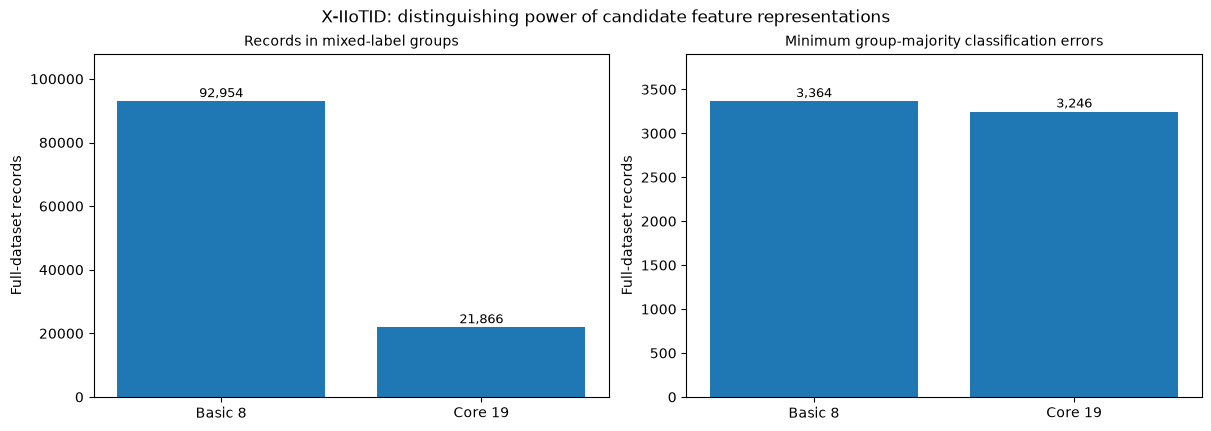

Saved: reports\figures\x_iiotid_signature_ambiguity_lower_bound_v1.png


In [2]:
def group_metrics(table):
    if table not in ('basic8', 'core19'):
        raise ValueError(table)
    sql = f"""SELECT
        COUNT(*) groups_total,
        SUM(normal_count+attack_count) rows_total,
        SUM(CASE WHEN normal_count+attack_count>1 THEN normal_count+attack_count ELSE 0 END) repeated_rows,
        SUM(CASE WHEN normal_count>0 AND attack_count>0 THEN 1 ELSE 0 END) conflicting_groups,
        SUM(CASE WHEN normal_count>0 AND attack_count>0 THEN normal_count+attack_count ELSE 0 END) conflicting_rows,
        SUM(CASE WHEN normal_count<attack_count THEN normal_count ELSE attack_count END) minority_label_rows,
        MAX(normal_count+attack_count) max_group_size
        FROM {table}"""
    row = pd.read_sql_query(sql, con).iloc[0].to_dict()
    result = {k:int(v) for k,v in row.items()}
    assert result['rows_total'] == EXPECTED_ROWS, f'{table} DB size does not match Notebook 04 results'
    return result
all_metrics = {'Basic 8':group_metrics('basic8'), 'Core 19':group_metrics('core19')}
result_summary = pd.DataFrame([
    {'Feature set': name, **x,
     'repeat_%': round(100*x['repeated_rows']/EXPECTED_ROWS,2),
     'conflict_%': round(100*x['conflicting_rows']/EXPECTED_ROWS,2),
     'majority_error_lower_bound_%':round(100*x['minority_label_rows']/EXPECTED_ROWS,3)}
    for name,x in all_metrics.items()
])
display(result_summary)

fig, axes = plt.subplots(1,2,figsize=(12,4.2),layout='constrained')
for ax, field, title in [
    (axes[0],'conflicting_rows','Records in mixed-label groups'),
    (axes[1],'minority_label_rows','Minimum group-majority classification errors')]:
    vals = [all_metrics[k][field] for k in ('Basic 8','Core 19')]
    bars = ax.bar(['Basic 8','Core 19'],vals)
    ax.set_title(title,fontsize=10)
    ax.set_ylabel('Full-dataset records')
    ax.set_ylim(0,max(vals)*1.16 if max(vals)>0 else 1)
    for b,v in zip(bars,vals):
        ax.annotate(f'{v:,}',(b.get_x()+b.get_width()/2,v),xytext=(0,3),
                    textcoords='offset points',ha='center',fontsize=9)
fig.suptitle('X-IIoTID: distinguishing power of candidate feature representations', fontsize=12)
p=FIG/'x_iiotid_signature_ambiguity_lower_bound_v1.png'
fig.savefig(p,dpi=170,bbox_inches='tight');plt.show()
print('Saved:', p.relative_to(ROOT))


## B. Inspect largest Core-19 groups

Notebook 04's database stores only hashed feature combinations and label counts. Select the largest groups and the largest mixed-label groups; then scan the original CSV to learn *what they represent*. Hashes are opaque identifiers, and IP addresses are **not** model features or report fields.


In [3]:
top_overall = pd.read_sql_query("""SELECT signature, normal_count, attack_count,
    normal_count+attack_count AS group_size
    FROM core19 ORDER BY group_size DESC, signature LIMIT 10""",con)
top_conflicts = pd.read_sql_query("""SELECT signature, normal_count, attack_count,
    normal_count+attack_count AS group_size
    FROM core19 WHERE normal_count>0 AND attack_count>0
    ORDER BY group_size DESC, signature LIMIT 12""",con)
all_top = pd.concat([top_overall,top_conflicts],ignore_index=True).drop_duplicates('signature')
chosen = all_top['signature'].tolist()
group_ids = {sig:f'G{i:02d}' for i,sig in enumerate(chosen,1)}
all_top['group_id'] = all_top['signature'].map(group_ids)
all_top['mixed_label'] = all_top.normal_count.gt(0) & all_top.attack_count.gt(0)
print('Selected distinct top groups:',len(all_top))
display(all_top[['group_id','normal_count','attack_count','group_size','mixed_label']])


Selected distinct top groups: 22


,group_id,normal_count,attack_count,group_size,mixed_label
0,G01,0,64194,64194,False
1,G02,0,2772,2772,False
2,G03,0,1918,1918,False
3,G04,0,1774,1774,False
4,G05,1687,0,1687,False
5,G06,1649,0,1649,False
6,G07,0,1584,1584,False
7,G08,1538,0,1538,False
8,G09,1519,0,1519,False
9,G10,1517,0,1517,False


## C. Rescan the CSV once and describe those selected groups

We reproduce **exactly Notebook 04's text normalization and BLAKE2b feature signatures**, allowing an apples-to-apples comparison. This uses chunked reading and collects only aggregates for the small number of selected groups. The main dataset stays read-only.

For each top group, inspect the distribution of `class1` / `class2`, count distinct timestamps / dates / source and destination addresses, and describe which of the 19 measurements are missing. We save only aggregate counts. A high concentration of one specific capture or attack type could expose an evaluation shortcut.


In [4]:
def normalize(series):
    s = series.fillna('').astype(str).str.strip()
    return s.mask(s.str.casefold().isin(PLACEHOLDERS), '<MISSING>')

def digest_values(values):
    h = hashlib.blake2b(digest_size=16)
    for v in values:
        b=str(v).encode('utf-8')
        h.update(len(b).to_bytes(4,'big'))
        h.update(b)
    return h.hexdigest()

header = pd.read_csv(CSV,nrows=0).columns.tolist()
metadata = [x for x in ['class1','class2','class3','Timestamp','Date','Scr_IP','Des_IP'] if x in header]
required = set(CORE+['class1','class2','class3'])
if not required.issubset(header):
    raise ValueError(f'CSV missing required columns: {required-set(header)}')
keep = set(chosen)
profiles = {sig:{'n':0,'binary':Counter(),'class1':Counter(),'class2':Counter(),
                 'missing':Counter(), 'feature_example':None,
                 'days':set(), 'times':set(), 'sources':set(), 'destinations':set()}
            for sig in chosen}
processed = 0
for part in pd.read_csv(CSV,usecols=list(dict.fromkeys(CORE+metadata)),
                        chunksize=40_000,dtype=str,keep_default_na=False,low_memory=False):
    normalized = pd.DataFrame({c:normalize(part[c]) for c in CORE},index=part.index)
    sigs = pd.Series([digest_values(row) for row in normalized.itertuples(index=False,name=None)],index=part.index)
    mask = sigs.isin(keep)
    if mask.any():
        for signature, ix in sigs[mask].groupby(sigs[mask]).groups.items():
            chosen_part = part.loc[ix]
            p=profiles[signature]
            p['n']+=len(chosen_part)
            for col,key in [('class3','binary'),('class2','class2'),('class1','class1')]:
                p[key].update(chosen_part[col].fillna('').str.strip().value_counts().to_dict())
            norm_piece=normalized.loc[ix]
            p['missing'].update(norm_piece.eq('<MISSING>').sum().astype(int).to_dict())
            if p['feature_example'] is None:
                p['feature_example'] = norm_piece.iloc[0].to_dict()
            for field,key in [('Date','days'),('Timestamp','times'),
                              ('Scr_IP','sources'),('Des_IP','destinations')]:
                if field in chosen_part:
                    p[key].update(chosen_part[field].astype(str).str.strip().unique().tolist())
    processed+=len(part)
    if processed % 200_000 < 40_000 or processed==EXPECTED_ROWS:
        print(f'Processed {processed:,} rows')
assert processed==EXPECTED_ROWS, 'Input CSV changed since Notebook 04; re-run Notebook 04 first.'
for r in all_top.itertuples(index=False):
    assert profiles[r.signature]['n']==int(r.group_size),         f'Feature signatures disagree with Notebook 04 for {r.group_id}. Check CSV and normalization.'
print('Matched all selected groups exactly to Notebook 04 DB. No raw rows exported.')


Processed 200,000 rows
Processed 400,000 rows
Processed 600,000 rows
Processed 800,000 rows
Processed 820,834 rows
Matched all selected groups exactly to Notebook 04 DB. No raw rows exported.


## D. Visual explanations of the dominant signatures

,group_id,size,normal,attack,mixed_label,dominant_class2,dominant_class2_count,missing_features,distinct_date_tokens,distinct_timestamp_tokens,distinct_source_ips,distinct_destination_ips
0,G01,64194,0,64194,False,RDOS,64194,6,1,633,2,1
1,G02,2772,0,2772,False,Reconnaissance,2772,0,1,4,1,1
2,G03,1918,0,1918,False,Reconnaissance,1918,0,1,4,1,1
3,G04,1774,0,1774,False,Reconnaissance,1774,10,3,67,1,1
4,G05,1687,1687,0,False,Normal,1687,0,42,1630,1,2
5,G06,1649,1649,0,False,Normal,1649,0,42,1600,1,2
6,G07,1584,0,1584,False,Reconnaissance,1584,0,2,66,1,1
7,G08,1538,1538,0,False,Normal,1538,6,42,1485,3,2
8,G09,1519,1519,0,False,Normal,1519,0,42,1485,1,2
9,G10,1517,1517,0,False,Normal,1517,10,42,1508,1,2


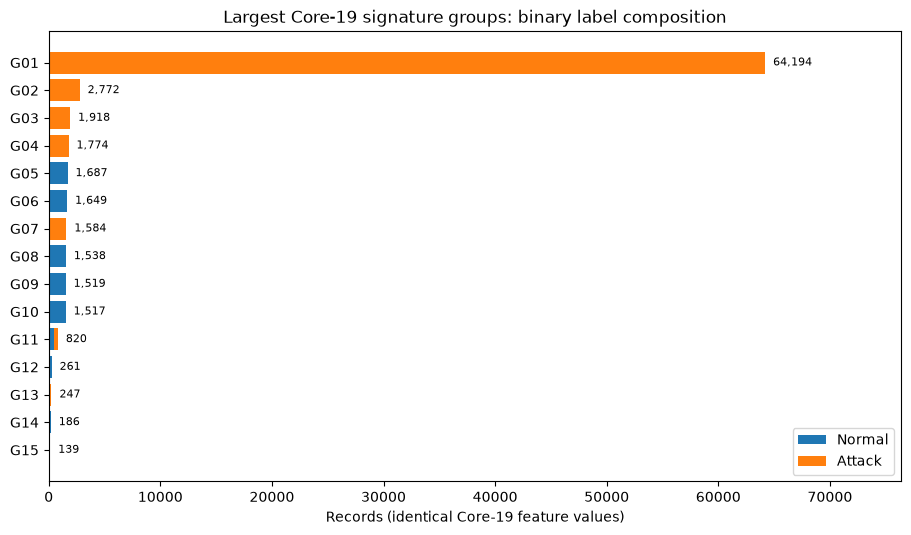

Saved: reports\figures\x_iiotid_dominant_core19_group_labels_v1.png


In [5]:
profile_rows=[]
for r in all_top.itertuples(index=False):
    p=profiles[r.signature]
    most_common_c2=p['class2'].most_common(1)
    profile_rows.append({
        'group_id':r.group_id,'size':int(p['n']),
        'normal':int(p['binary'].get('Normal',0)),
        'attack':int(p['binary'].get('Attack',0)),
        'mixed_label':bool(r.mixed_label),
        'dominant_class2':most_common_c2[0][0] if most_common_c2 else '',
        'dominant_class2_count':most_common_c2[0][1] if most_common_c2 else 0,
        'missing_features':sum(v== '<MISSING>' for v in p['feature_example'].values()),
        'distinct_date_tokens':len(p['days']),
        'distinct_timestamp_tokens':len(p['times']),
        'distinct_source_ips':len(p['sources']),
        'distinct_destination_ips':len(p['destinations'])
    })
profile_table=pd.DataFrame(profile_rows)
display(profile_table)

# Figure 2: size and binary class composition of dominant signatures.
plot=profile_table.sort_values('size').tail(15)
y=np.arange(len(plot))
fig,ax=plt.subplots(figsize=(11,max(5,len(plot)*.39)))
ax.barh(y,plot['normal'],label='Normal')
ax.barh(y,plot['attack'],left=plot['normal'],label='Attack')
ax.set_yticks(y,plot['group_id'])
ax.set_xlabel('Records (identical Core-19 feature values)')
ax.set_title('Largest Core-19 signature groups: binary label composition')
ax.legend()
for i,n in enumerate(plot['size']): ax.text(n, i, f'  {n:,}',va='center',fontsize=8)
ax.set_xlim(0,max(plot['size'])*1.19)
p=FIG/'x_iiotid_dominant_core19_group_labels_v1.png'
fig.savefig(p,dpi=170,bbox_inches='tight');plt.show()
print('Saved:', p.relative_to(ROOT))


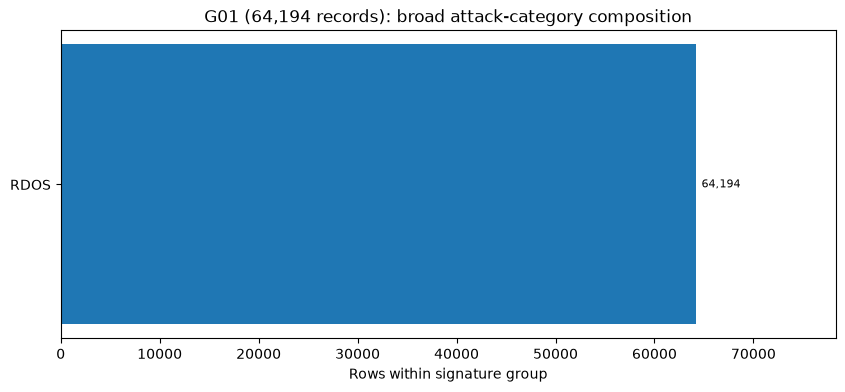

Saved: reports\figures\x_iiotid_largest_signature_attack_categories_v1.png
Largest Core-19 group example (not an IP/label; shown for feature diagnosis):


,Feature value
Protocol,udp
Service,coap
Duration,<MISSING>
Scr_bytes,<MISSING>
Des_bytes,<MISSING>
Conn_state,1
is_syn_only,FALSE
Is_SYN_ACK,FALSE
is_pure_ack,FALSE
is_with_payload,TRUE


Distinct source IPs: 2 destination IPs: 1
Distinct timestamp strings: 633 date strings: 1


In [6]:
# Figure 3: Which *broad* attack categories dominate the largest network-signature group?
lead_sig=all_top.sort_values('group_size',ascending=False).iloc[0]['signature']
lead_id=group_ids[lead_sig]
lead=profiles[lead_sig]
top_cats=lead['class2'].most_common(12)
labels=[x[0] for x in top_cats][::-1]
counts=[x[1] for x in top_cats][::-1]
fig,ax=plt.subplots(figsize=(10,max(4,len(labels)*.46)))
bars=ax.barh(np.arange(len(labels)),counts)
ax.set_yticks(np.arange(len(labels)),labels)
ax.set_xlabel('Rows within signature group')
ax.set_title(f'{lead_id} ({lead["n"]:,} records): broad attack-category composition')
for bar,value in zip(bars,counts):
    ax.annotate(f'{value:,}',(value,bar.get_y()+bar.get_height()/2),xytext=(4,0),
                textcoords='offset points',va='center',fontsize=8)
ax.set_xlim(0,max(counts)*1.22 if counts else 1)
p=FIG/'x_iiotid_largest_signature_attack_categories_v1.png'
fig.savefig(p,dpi=170,bbox_inches='tight');plt.show()
print('Saved:',p.relative_to(ROOT))

print('Largest Core-19 group example (not an IP/label; shown for feature diagnosis):')
display(pd.DataFrame([lead['feature_example']]).T.rename(columns={0:'Feature value'}))
print('Distinct source IPs:',len(lead['sources']),'destination IPs:',len(lead['destinations']))
print('Distinct timestamp strings:',len(lead['times']),'date strings:',len(lead['days']))


## E. Decision gate and export

**Decision rule:** Even if the overall label balance looks good, we **do not** randomly split these rows yet. The same feature group could appear in train and test, producing an inflated test score. Session/capture and source grouping still require separate verification. The majority-label error bound is only descriptive and should never be called test performance.

**Don't delete conflicting rows indiscriminately.** They might represent genuinely indistinguishable network states. We need to evaluate more trustworthy inputs, temporal context, or choose a carefully documented binary-detection limitation. Also consider a missingness-only baseline on a future isolated split to assess whether missing-value patterns are acting as a shortcut.


In [7]:
summary_csv = AUDIT/'x_iiotid_signature_ambiguity_metrics_v1.csv'
profile_csv = AUDIT/'x_iiotid_dominant_group_profiles_v1.csv'
summary_json = AUDIT/'x_iiotid_dominant_signature_diagnostics_v1.json'
md_path = DOCS/'X_IIOTID_DOMINANT_SIGNATURE_DIAGNOSTICS_V1.md'
result_summary.to_csv(summary_csv,index=False)
profile_table.to_csv(profile_csv,index=False)
export={
    'dataset': CSV.name,
    'records_verified': processed,
    'notebook04_summary_reused': PREV.name,
    'group_hash_algorithm': 'BLAKE2b-128 length-prefixed normalized string cells; same as Notebook 04',
    'feature_sets':{'basic8': BASIC,'core19':CORE},
    'group_metrics':all_metrics,
    'top_groups':profile_table.to_dict('records'),
    'largest_group_id':lead_id,
    'largest_group_class2':dict(lead['class2']),
    'largest_group_class1':dict(lead['class1']),
    'largest_group_example_core19_features':lead['feature_example'],
    'raw_ips_exported':False,
    'trained_model':False,'split_created':False,
    'next_phase':'Verify session/time/device grouping and feature semantics; test missingness shortcut using leakage-controlled holdout'
}
summary_json.write_text(json.dumps(export,indent=2,ensure_ascii=False,default=int),encoding='utf-8')
md_path.write_text(f"""# X-IIoTID: dominant Core-19 signature investigation (V1)

- Original full CSV scanned and matched Notebook 04 SQLite evidence: **{processed:,} rows**.
- Largest identical-feature group: **{lead_id}**, **{lead['n']:,} rows**.
- Largest group class3: **Normal {lead['binary'].get('Normal',0):,}** / **Attack {lead['binary'].get('Attack',0):,}**.
- Basic 8 records in mixed-label groups: **{all_metrics['Basic 8']['conflicting_rows']:,}**.
- Core 19 records in mixed-label groups: **{all_metrics['Core 19']['conflicting_rows']:,}**.
- Basic 8 group-majority *in-sample* minimum errors: **{all_metrics['Basic 8']['minority_label_rows']:,}**.
- Core 19 group-majority *in-sample* minimum errors: **{all_metrics['Core 19']['minority_label_rows']:,}**.

## Interpreting the findings

These metrics describe ambiguity among observed feature combinations. They are **not validation accuracy, test accuracy, or proof of incorrect labels**. The network-only signatures omit session identity, raw metadata and potentially important temporal context. Missing-value patterns could also reflect capture procedures rather than attacker behaviour.

## Saved research outputs

- `reports/audits/{summary_csv.name}`
- `reports/audits/{profile_csv.name}`
- `reports/audits/{summary_json.name}`
- `reports/figures/x_iiotid_signature_ambiguity_lower_bound_v1.png`
- `reports/figures/x_iiotid_dominant_core19_group_labels_v1.png`
- `reports/figures/x_iiotid_largest_signature_attack_categories_v1.png`

## Next research gate

Before the 70/15/15 split, verify capture/session/time/source grouping and network gateway measurability. Avoid random row-level splitting and preserve the unmodified source CSV.
""",encoding='utf-8')
print('Saved:',summary_csv.relative_to(ROOT), profile_csv.relative_to(ROOT))
print('Saved:',summary_json.relative_to(ROOT),md_path.relative_to(ROOT))
print('COMPLETE. No split created and no model trained.')
con.close()


Saved: reports\audits\x_iiotid_signature_ambiguity_metrics_v1.csv reports\audits\x_iiotid_dominant_group_profiles_v1.csv
Saved: reports\audits\x_iiotid_dominant_signature_diagnostics_v1.json docs\X_IIOTID_DOMINANT_SIGNATURE_DIAGNOSTICS_V1.md
COMPLETE. No split created and no model trained.


## F. Git commit after verifying the output

In **VS Code PowerShell terminal** (not in a notebook Python cell):

```powershell
Set-Location 'D:\J26-CS-336-Network-Flow-V2-Git'
git branch --show-current
# Commit Notebook 04 first if its output has not yet been committed.
git add -- network_flow_v2/notebooks/x_iiotid/05_x_iiotid_dominant_signature_diagnostics.ipynb
git add -- network_flow_v2/reports/audits/x_iiotid_signature_ambiguity_metrics_v1.csv
git add -- network_flow_v2/reports/audits/x_iiotid_dominant_group_profiles_v1.csv
git add -- network_flow_v2/reports/audits/x_iiotid_dominant_signature_diagnostics_v1.json
git add -- network_flow_v2/reports/figures/x_iiotid_signature_ambiguity_lower_bound_v1.png
git add -- network_flow_v2/reports/figures/x_iiotid_dominant_core19_group_labels_v1.png
git add -- network_flow_v2/reports/figures/x_iiotid_largest_signature_attack_categories_v1.png
git add -- network_flow_v2/docs/X_IIOTID_DOMINANT_SIGNATURE_DIAGNOSTICS_V1.md
git diff --cached --name-only
git diff --cached --check
# If staged files are exactly the intended results:
git commit -m 'research: diagnose X-IIoTID dominant network signatures'
git push
```

**Share back:** the two-row **Basic 8/Core 19 group-metrics table**, the **dominant-group profile table**, and the **largest group's Core-19 feature values**. We can then decide how to validate the split without over-claiming APT detection.
